In [7]:
import numpy as np
import tensorflow as tf
import random
import sys

print("Downloading text corpus...")
# Using a classic text corpus for the model to learn character sequences
path = tf.keras.utils.get_file('nietzsche.txt', origin='https://s3.amazonaws.com/text-datasets/nietzsche.txt')
text = open(path, 'rb').read().decode(encoding='utf-8').lower()

# Using a subset of 100k characters for faster training on standard hardware
text = text[:100000]
print(f"Corpus length used: {len(text)} characters")

600901/600901 ━━━━━━━━━━━━━━━━━━━━ 2s 4us/step
Corpus length used: 100000 characters


In [8]:
print("Creating character mappings...")
chars = sorted(list(set(text)))
char_indices = dict((c, i) for i, c in enumerate(chars))
indices_char = dict((i, c) for i, c in enumerate(chars))
print(f"Total unique characters: {len(chars)}")

print("Cutting text into sequences...")
maxlen = 40
step = 3
sentences = []
next_chars = []
for i in range(0, len(text) - maxlen, step):
    sentences.append(text[i: i + maxlen])
    next_chars.append(text[i + maxlen])
print(f"Number of training sequences: {len(sentences)}")

Creating character mappings...
Total unique characters: 52
Cutting text into sequences...
Number of training sequences: 33320


In [9]:
print("Vectorizing data (One-Hot Encoding)...")
# Create empty arrays
X = np.zeros((len(sentences), maxlen, len(chars)), dtype=bool)
y = np.zeros((len(sentences), len(chars)), dtype=bool)

# Fill the arrays based on the character mappings
for i, sentence in enumerate(sentences):
    for t, char in enumerate(sentence):
        X[i, t, char_indices[char]] = 1
    y[i, char_indices[next_chars[i]]] = 1
    
print(f"X shape (Input sequences): {X.shape}")
print(f"y shape (Target characters): {y.shape}")

Vectorizing data (One-Hot Encoding)...
X shape (Input sequences): (33320, 40, 52)
y shape (Target characters): (33320, 52)


In [28]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

print("Building the Character-Level RNN Model...")
model = Sequential([
    LSTM(128, input_shape=(maxlen, len(chars))),
    Dense(len(chars), activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy'])
model.summary()

print("Training the model... (This will take a few minutes)")
# Train the model
history = model.fit(X, y, batch_size=128, epochs=50)

Building the Character-Level RNN Model...


C:\Users\dp185\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 128)            │        92,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,380 (388.20 KB)

 Trainable params: 99,380 (388.20 KB)

 Non-trainable params: 0 (0.00 B)

Training the model... (This will take a few minutes)
Epoch 1/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.1613 - loss: 3.0013
Epoch 2/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.2516 - loss: 2.7213
Epoch 3/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.2871 - loss: 2.5207
Epoch 4/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.2992 - loss: 2.4296
Epoch 5/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.3155 - loss: 2.3709
Epoch 6/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.3270 - loss: 2.3254
Epoch 7/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.3377 - loss: 2.2877
Epoch 8/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.3444 - loss: 2.2545
Epoch 9/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.3522 - loss: 2.2241
Epoch 10/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.3591 - loss: 2.1971
Epoch 11/50
261/261 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.3657 - l

In [29]:
def generate_text(model, seed_text, length=400, temperature=0.5):
    generated = seed_text
    print(f'\n--- Generating new text with seed: "{seed_text}" ---\n')
    print(generated, end="")
    
    for i in range(length):
        # Vectorize the current seed text
        x_pred = np.zeros((1, maxlen, len(chars)))
        for t, char in enumerate(seed_text):
            x_pred[0, t, char_indices[char]] = 1.
            
        # Predict the probability of the next character
        preds = model.predict(x_pred, verbose=0)[0]
        
        # Apply "temperature" to add randomness/creativity
        preds = np.asarray(preds).astype('float64')
        preds = np.log(preds + 1e-7) / temperature
        exp_preds = np.exp(preds)
        preds = exp_preds / np.sum(exp_preds)
        
        # Sample the next character index
        probas = np.random.multinomial(1, preds, 1)
        next_index = np.argmax(probas)
        next_char = indices_char[next_index]
        
        # Append to generated string and slide the window over by 1 character
        generated += next_char
        seed_text = seed_text[1:] + next_char
        
        print(next_char, end="")
        sys.stdout.flush()
    print("\n")

# Pick a random starting point and generate!
start_index = random.randint(0, len(text) - maxlen - 1)
random_seed = text[start_index: start_index + maxlen]

generate_text(model, random_seed)


--- Generating new text with seed: "too
human; and who should, nevertheless," ---

too
human; and who should, nevertheless, and as a propement of the ane and as a sore farted and the part of preart the perspessest has so the self-caliences it an the was a sore and the one that with seners the one the theres of the in the which plose devers of a rearns and mose is the entines well the
erertion of which it is as a seeal a beto de is the withoun of the solien sour not in the was impeat to the porsentay for the pristion o



RNN is thinking of new text...
RNN Generated: 'f the one gore proble for are moral'
Translating RNN output to handwriting...


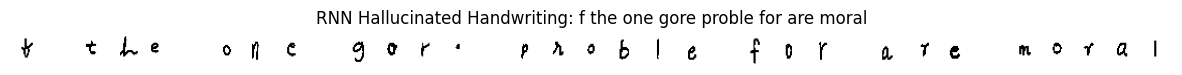

In [32]:
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np
import random

# 1. Let the RNN autonomously generate a sequence of text
def get_rnn_text(model, seed_text, length=30, temperature=0.5):
    generated = ""
    current_seed = seed_text
    
    for i in range(length):
        # Vectorize the current seed
        x_pred = np.zeros((1, maxlen, len(chars)))
        for t, char in enumerate(current_seed):
            x_pred[0, t, char_indices[char]] = 1.
            
        # Predict next character
        preds = model.predict(x_pred, verbose=0)[0]
        preds = np.asarray(preds).astype('float64')
        preds = np.log(preds + 1e-7) / temperature
        exp_preds = np.exp(preds)
        preds = exp_preds / np.sum(exp_preds)
        
        probas = np.random.multinomial(1, preds, 1)
        next_index = np.argmax(probas)
        next_char = indices_char[next_index]
        
        # Add to our generated string and slide the window
        generated += next_char
        current_seed = current_seed[1:] + next_char
        
    return generated

# Pick a random starting point from our text corpus to feed the RNN
start_index = random.randint(0, len(text) - maxlen - 1)
random_seed = text[start_index: start_index + maxlen]

print("RNN is thinking of new text...")
# Generate 35 characters (keeping it short so the image fits on the screen)
autonomous_text = get_rnn_text(model, random_seed, length=35)
print(f"RNN Generated: '{autonomous_text}'")

# 2. Convert the autonomously generated text into handwritten images
def generate_handwritten_image(text, dataset_df, img_dir, img_height=32, img_width=32):
    images_to_stitch = []
    
    for char in text:
        # Check if character is a space or punctuation not in our image dataset
        if char == ' ' or char not in dataset_df['label'].astype(str).values:
            blank_space = np.ones((img_height, img_width), dtype=np.uint8) * 255
            images_to_stitch.append(blank_space)
        else:
            # STRICT CASE MATCHING
            matching_rows = dataset_df[dataset_df['label'].astype(str) == char]
            
            if len(matching_rows) > 0:
                img_name = random.choice(matching_rows['image'].values)
                img_path = os.path.join(img_dir, img_name)
                
                char_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                if char_img is not None:
                    char_img = cv2.resize(char_img, (img_width, img_height))
                    images_to_stitch.append(char_img)
            else:
                blank_space = np.ones((img_height, img_width), dtype=np.uint8) * 255
                images_to_stitch.append(blank_space)
                
    if images_to_stitch:
        return cv2.hconcat(images_to_stitch)
    return None

print("Translating RNN output to handwriting...")
final_handwritten_img = generate_handwritten_image(autonomous_text, df, 'dataset/')

if final_handwritten_img is not None:
    plt.figure(figsize=(15, 3))
    plt.imshow(final_handwritten_img, cmap='gray')
    plt.axis('off')
    plt.title(f"RNN Hallucinated Handwriting: {autonomous_text}")
    plt.show()